Import Utilities

In [10]:
import requests
import shutil
import csv
import os
import random
from tqdm import tqdm
import urllib

Download images from CSV file

In [11]:
def download_images(csv_file, image_folder, number_of_images_per_class):
    with open(csv_file, 'r') as file:
        reader = csv.reader(file)
        next(reader)  # Skip header row

        rows = list(reader)
        if number_of_images_per_class > len(rows):
            print(f"Requested {number_of_images_per_class} images, but only {len(rows)} are available. Downloading all available images.")
            number_of_images_per_class = len(rows)
        random_rows = random.sample(rows, number_of_images_per_class)

        for row in tqdm(random_rows):
            image_url = row[1]
            extension = os.path.splitext(urllib.parse.urlparse(image_url).path)[1]
            filename = row[0] + extension
            file_path = os.path.join(image_folder, filename)

            try:
                response = requests.get(image_url, stream=True)
                response.raise_for_status()  # Check if the request was successful

                with open(file_path, 'wb') as out_file:
                    shutil.copyfileobj(response.raw, out_file)

            except requests.exceptions.RequestException as e:
                print(f"Failed to download {image_url}: {e}")

In [12]:
root_dir = "./"
csv_files = os.path.join(root_dir, "csv_files/")
os.makedirs(os.path.join(root_dir, "images/"), exist_ok=True) # Create images directory if it doesn't exist
image_folders = os.path.join(root_dir, "images")

In [13]:
number_of_images_per_class = 350

for each_csv in os.listdir(csv_files):
    folder_name = each_csv.split(".")[0]
    # Create a folder for each class
    os.makedirs(os.path.join(image_folders, folder_name), exist_ok=True)
    csv_file = os.path.join(csv_files, each_csv)
    image_folder = os.path.join(image_folders, folder_name)
    download_images(csv_file, image_folder, number_of_images_per_class)

100%|██████████| 350/350 [13:37<00:00,  2.34s/it]


KerasHub

Import and check versions of tensorflow and keras

In [20]:
os.environ["KERAS_BACKEND"] = "tensorflow" #set Keras backend to TensorFlow
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2" #show only error messages, to avoid printing a tonne of verbose warnings!

import tensorflow as tf
tf.get_logger().setLevel('ERROR') #set TensorFlow logger level to ERROR 
print("tensorflow: ",tf.__version__)

import keras
print("keras: ",keras.__version__)

import keras_hub
print("keras hub: ",keras_hub.__version__)

import keras_cv
print("keras cv: ",keras_cv.__version__)

tensorflow:  2.20.0
keras:  3.14.1
keras hub:  0.29.0
keras cv:  0.9.0


List pre-trained models

In [21]:
print(keras_hub.models.ImageObjectDetector.presets.keys())

dict_keys(['dfine_nano_coco', 'dfine_small_coco', 'dfine_medium_coco', 'dfine_large_coco', 'dfine_xlarge_coco', 'dfine_small_obj365', 'dfine_medium_obj365', 'dfine_large_obj365', 'dfine_xlarge_obj365', 'dfine_small_obj2coco', 'dfine_medium_obj2coco', 'dfine_large_obj2coco_e25', 'dfine_xlarge_obj2coco', 'retinanet_resnet50_fpn_coco', 'retinanet_resnet50_fpn_v2_coco'])


Using RetinaNet as our auto-annotator and object detector
Pretrained on MS COCO

In [22]:
retinanet = keras_hub.models.RetinaNetObjectDetector.from_preset(
    "retinanet_resnet50_fpn_coco"
)

Preview performance

In [23]:
image_size=(800, 800)
batch_size=8

image_dir = "./images/"

tf_dataset = keras.utils.image_dataset_from_directory(
    image_dir,
    image_size=image_size,
    batch_size=batch_size,
    pad_to_aspect_ratio=True
)

Found 582 files belonging to 1 classes.


Class mapping definition

In [24]:
class_mapping = {
    1: "person", 2: "bicycle", 3: "car", 4: "motorcycle", 5: "airplane", 6: "bus", 7: "train", 8: "truck", 9: "boat",
    10: "traffic light", 11: "fire hydrant", 13: "stop sign", 14: "parking meter", 15: "bench", 16: "bird", 17: "cat", 
    18: "dog", 19: "horse", 20: "sheep", 21: "cow", 22: "elephant", 23: "bear", 24: "zebra", 25: "giraffe",
    27: "backpack", 28: "umbrella", 31: "handbag", 32: "tie", 33: "suitcase", 34: "frisbee", 35: "skis", 36: "snowboard",
    37: "sports ball", 38: "kite", 39: "baseball bat", 40: "baseball glove", 41: "skateboard", 42: "surfboard",
    43: "tennis racket", 44: "bottle", 46: "wine glass", 47: "cup", 48: "fork", 49: "knife", 50: "spoon", 51: "bowl",
    52: "banana", 53: "apple", 54: "sandwich", 55: "orange", 56: "broccoli", 57: "carrot", 58: "hot dog", 59: "pizza", 
    60: "donut", 61: "cake", 62: "chair", 63: "couch", 64: "potted plant", 65: "bed", 67: "dining table", 70: "toilet", 
    72: "tv", 73: "laptop", 74: "mouse", 75: "remote", 76: "keyboard", 77: "cell phone", 78: "microwave", 79: "oven",
    80: "toaster", 81: "sink", 82: "refrigerator", 84: "book", 85: "clock", 86: "vase", 87: "scissors", 88: "teddy bear",
    89: "hair drier", 90: "toothbrush"
}

Quality Check

(8, 800, 800, 3)


2026-05-17 17:33:25.545403: E tensorflow/core/lib/jpeg/jpeg_mem.cc:329] Premature end of JPEG data. Stopped at line 302/500


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 830ms/step
(8, 800, 800, 3)
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 805ms/step


2026-05-17 17:33:28.240757: I tensorflow/core/framework/local_rendezvous.cc:407] Local rendezvous is aborting with status: OUT_OF_RANGE: End of sequence


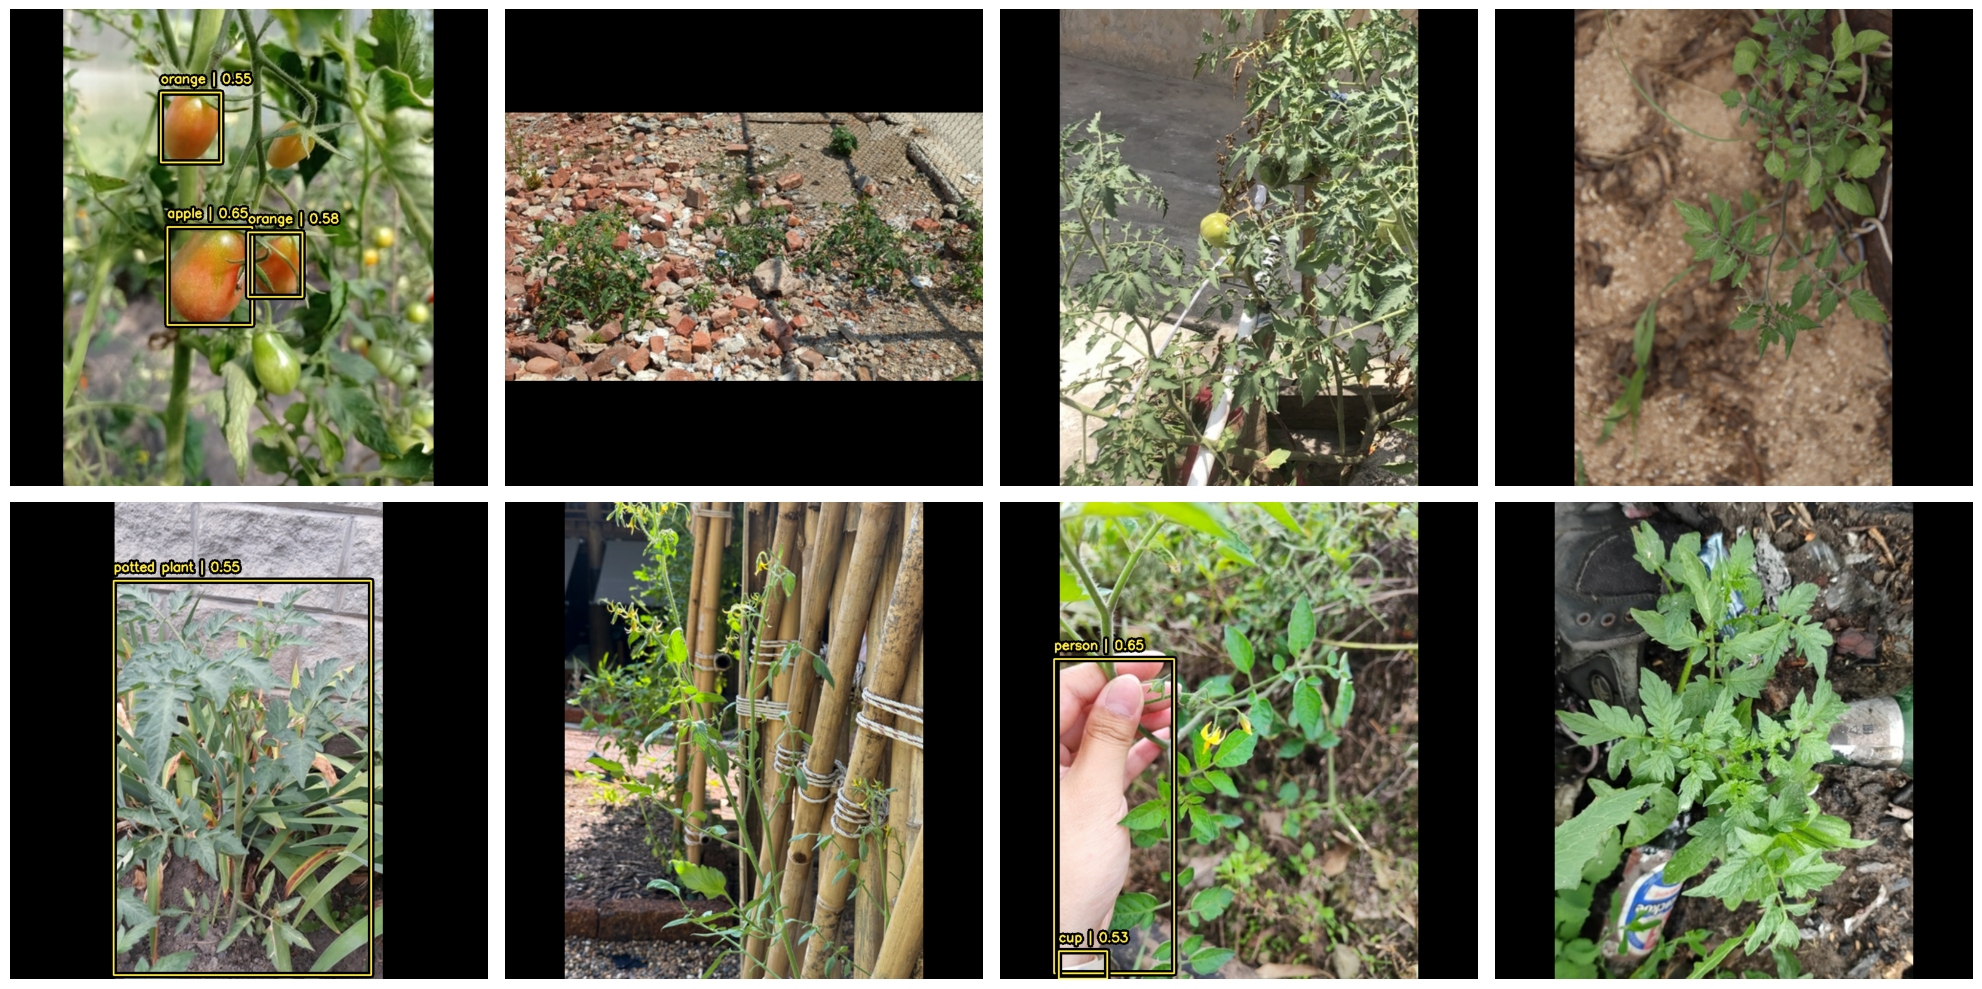

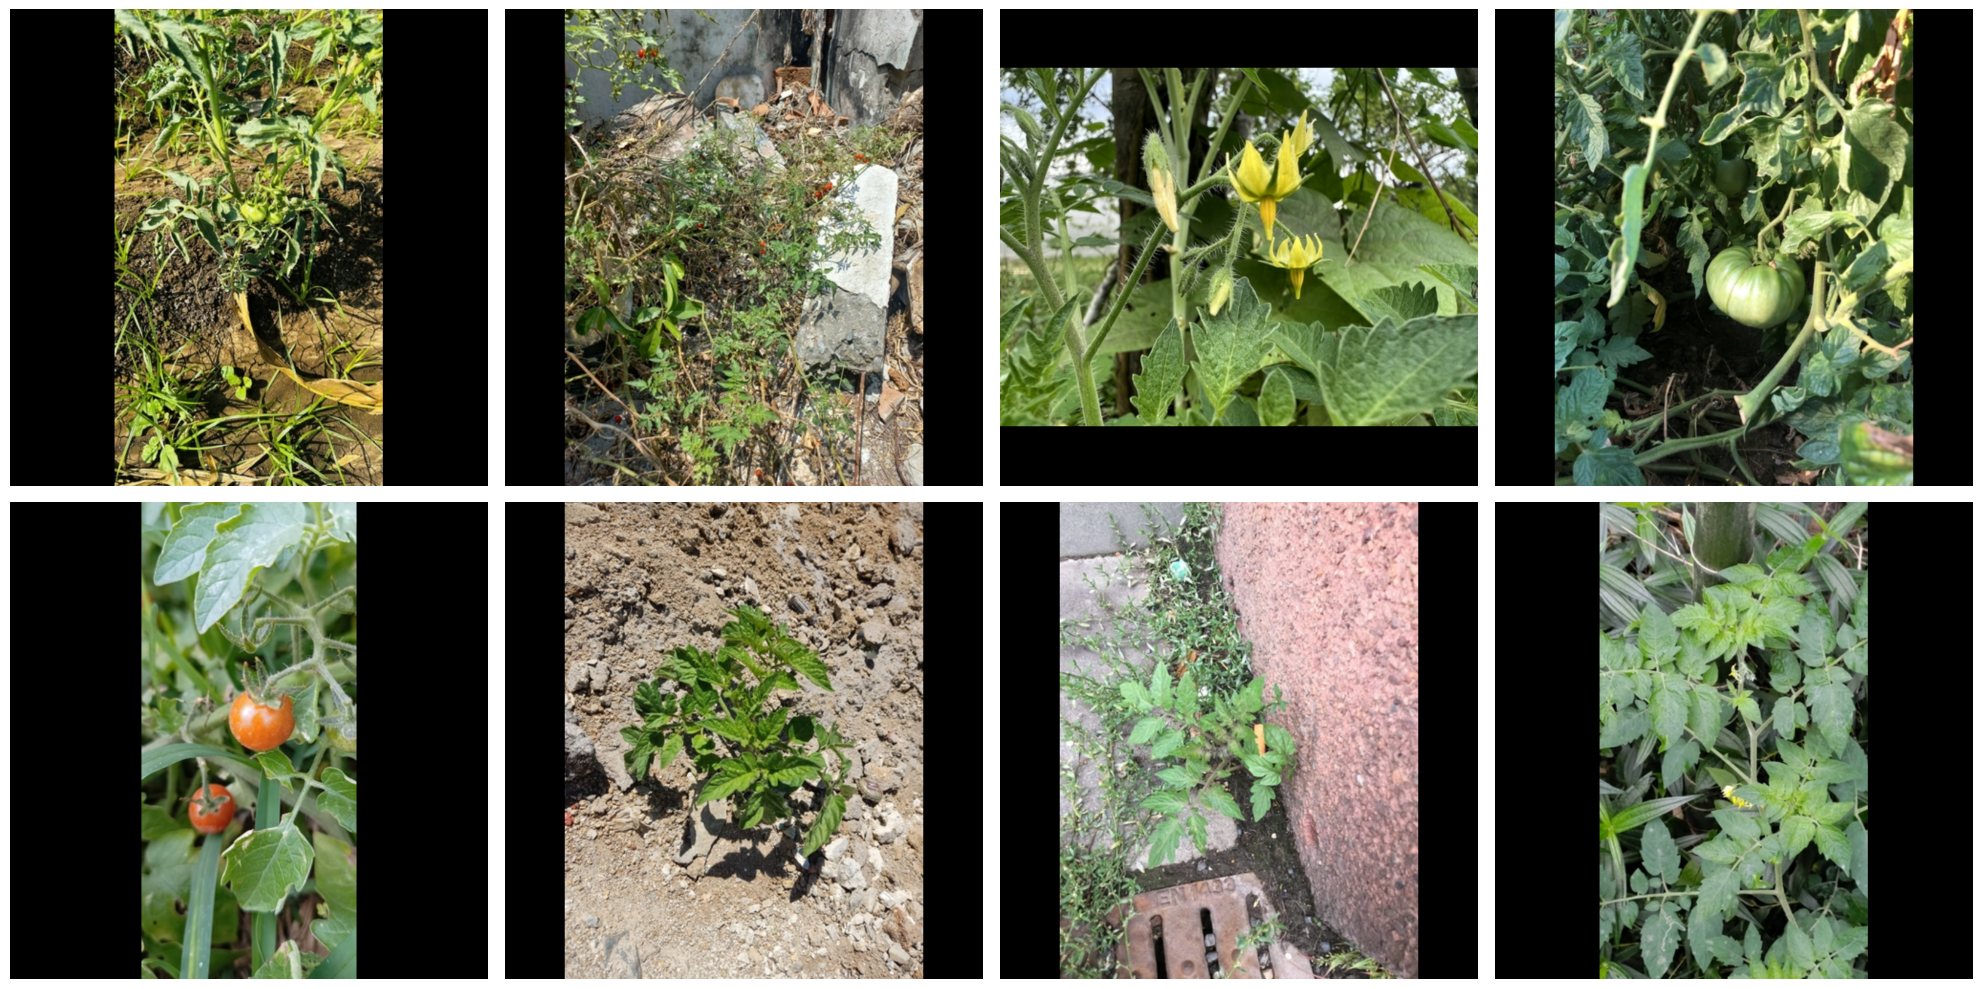

In [27]:
from keras_cv import visualization

tf_dataset = tf_dataset.apply(tf.data.experimental.ignore_errors())

for images, labels in tf_dataset.take(2):
    print(images.shape)

    y_pred = retinanet.predict(images)

    keras_cv_preds = {
        "boxes": y_pred["boxes"],
        "classes": y_pred["labels"],
        "confidence": y_pred["confidence"],
    }
    visualization.plot_bounding_box_gallery(
        images,
        value_range=(0, 255),
        rows=2,
        cols=4,
        y_pred=keras_cv_preds,
        scale=5,
        font_scale=0.7,
        bounding_box_format="yxyx",
        class_mapping=class_mapping
    )

Training auto-annotator

In [1]:
import os
import requests
from pycocotools.coco import COCO
from tqdm import tqdm

from concurrent.futures import ThreadPoolExecutor

ANN_FILE = "instances_train2017.json"
SAVE_DIR = "./coco_tomatoes"
LIMIT = 1500
MAX_WORKERS = 20

os.makedirs(SAVE_DIR, exist_ok=True)
coco = COCO(ANN_FILE)

catIds = coco.getCatIds(catNms=["tomato"])
imgIds = coco.getImgIds(catIds=catIds)
images = coco.loadImgs(imgIds[:LIMIT])

loading annotations into memory...
Done (t=6.48s)
creating index...
index created!


Download images

In [2]:
def download_image(img):
    file_path = os.path.join(SAVE_DIR, img['file_name'])
    if not os.path.exists(file_path):
        try:
            response = requests.get(img['coco_url'], timeout=10)
            if response.status_code == 200:
                with open(file_path, 'wb') as f:
                    f.write(response.content)
        except Exception as e:
            return f"Error downloading {img['file_name']}: {e}"
    return f"Exists: {img['file_name']}"

print(f"Starting parallel download of {len(images)} images...")

with ThreadPoolExecutor(max_workers=MAX_WORKERS) as executor:
    results = list(tqdm(executor.map(download_image, images), total=len(images)))

print(f"\nFinished! Images are located in: {SAVE_DIR}")

Starting parallel download of 1500 images...


100%|██████████| 1500/1500 [01:33<00:00, 16.12it/s]


Finished! Images are located in: ./coco_tomatoes


Visualise a random image and print annotation data

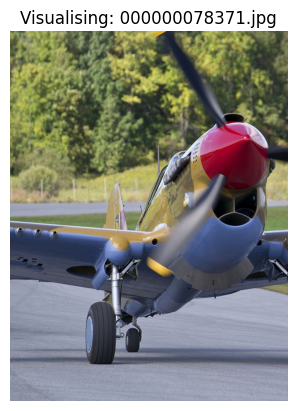

Image ID: 78371 | Resolution: 480x640

[Object 1]
  Category: airplane
  BBox (x, y, w, h): [1.45, 0.0, 478.55, 578.08]


In [3]:
import json
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# load the annotation file
with open(ANN_FILE, 'r') as f:
    data = json.load(f)

# get a list of downloaded images
images = [f for f in os.listdir(SAVE_DIR) if f.endswith(('.jpg', 'jpeg', 'png'))]
# grab an image (choose any random index)
image_filename = images[384]  # change this index to view different images
# find the image metadata (in the json file)
img_metadata = next((img for img in data['images'] if img['file_name'] == image_filename), None)

if img_metadata:
    img_id = img_metadata['id']
    # get categories and annotations
    categories = {cat['id']: cat['name'] for cat in data['categories']}
    img_anns = [ann for ann in data['annotations'] if ann['image_id'] == img_id]

    # display the image
    img_path = os.path.join(SAVE_DIR, image_filename)
    img = mpimg.imread(img_path)
    plt.imshow(img)
    plt.title(f"Visualising: {image_filename}")
    plt.axis('off')
    plt.show()

    # print the annotations data
    print(f"Image ID: {img_id} | Resolution: {img_metadata['width']}x{img_metadata['height']}")
    if not img_anns:
        print("No annotations found for this image in the JSON.")
    else:
        for i, ann in enumerate(img_anns):
            cat_name = categories.get(ann['category_id'], "Unknown")
            print(f"\n[Object {i+1}]")
            print(f"  Category: {cat_name}")
            print(f"  BBox (x, y, w, h): {ann['bbox']}")

Overlay boxes and class labels 